# 02 — Hypothesis Test & Power Analysis

In [1]:
import os
import sys
from pathlib import Path
import duckdb

if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, str(Path.cwd())) # supaya "from src ...." bisa di-import

from src.stats_utils import two_proportion_ztest, diff_confidence_interval, lift

# read_only : notebook ini hanya membaca tabel yang membuat di notebook 01
con = duckdb.connect("data/processed/ab_test.duckdb", read_only=True)

In [2]:
summary = con.sql(
    Path("sql/03_conversion_by_group.sql").read_text()
).df().set_index("test_group")
summary

,n_users,n_converted,conversion_rate_pct
test_group,,,
ad,564577,14423,2.555
psa,23524,420,1.785


In [3]:
x1, n1 = summary.loc["ad", "n_converted"], summary.loc["ad", "n_users"]
x2, n2 = summary.loc["psa", "n_converted"], summary.loc["psa", "n_users"]
print(f"ad : {x1} / {n1}")
print(f"psa: {x2} / {n2}")

ad : 14423 / 564577
psa: 420 / 23524


In [4]:
z, p_value = two_proportion_ztest(x1, n1, x2, n2)
ci_low, ci_high = diff_confidence_interval(x1, n1, x2, n2)
abs_lift, rel_lift = lift(x1, n1, x2, n2)

print(f"z statistic     : {z:.3f}")
print(f"p-value         : {p_value:.2e}")
print(f"absolute lift   : {abs_lift * 100:.3f} pp")
print(f"95% CI (diff)   : [{ci_low * 100:.3f} pp, {ci_high * 100:.3f} pp]")
print(f"relative lift       : {rel_lift * 100:.1f}%")

z statistic     : 7.370
p-value         : 1.71e-13
absolute lift   : 0.769 pp
95% CI (diff)   : [0.595 pp, 0.943 pp]
relative lift       : 43.1%


In [5]:
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

z_sm, p_sm = proportions_ztest(count=[x1, x2], nobs=[n1, n2])
ci_sm = confint_proportions_2indep(x1, n1, x2, n2, compare="diff", method="wald")

print(f"statsmodels z       : {z_sm:.3f}")
print(f"statsmodels p-value : {p_sm:.2e}")
print(f"statsmodels 95% CI  : [{ci_sm[0] * 100:.3f} pp, {ci_sm[1] * 100:.3f} pp]")

statsmodels z       : 7.370
statsmodels p-value : 1.71e-13
statsmodels 95% CI  : [0.595 pp, 0.943 pp]


### Results

| Metric | Value |
|---|---|
| Conversion rate — ad | 2.555% (14,423 / 564,577) |
| Conversion rate — psa | 1.785% (420 / 23,524) |
| Absolute lift | +0.769 pp |
| 95% CI for the difference | [0.595 pp, 0.943 pp] |
| Relative lift | +43.1% |
| z statistic | 7.37 |
| p-value | 1.7 × 10⁻¹³ |

The manual implementation in `src/stats_utils.py` matches statsmodels exactly.

### Interpretation
- **Statistically significant:** p < 0.05 and the 95% CI excludes 0,
  so we reject H0. If ads had no effect, a difference this large would
  be extremely unlikely to arise by chance.
- **Practical significance:** no business threshold was pre-registered
  (see the Amendment in the experiment brief). The 95% CI shows the
  true lift is plausibly at least ~0.6 pp, a substantial increase over
  the control rate of 1.79%. Any business threshold below ~0.6 pp is
  met even under a conservative estimate.
- **Note on relative lift:** the control group is small (420
  conversions), so the relative lift is sensitive to uncertainty in
  the control rate. Absolute lift with its CI is the primary result.

**Decision:** the effect is statistically significant and its plausible
size (≥0.6 pp) is substantial relative to the baseline → continue the
campaign, pending a cost-benefit check once ad cost data is available.

## Power analysis & minimum detectable effect (MDE)
How sensitive is this experiment? Given the sample sizes, what is the
smallest true lift we could reliably detect (80% power, α = 0.05)?

In [6]:
from src.stats_utils import mde_two_proportions, power_two_proportions

p_control = x2 / n2
mde_abs = mde_two_proportions(p_control, n1, n2)

print(f"baseline (psa) conversion : {p_control * 100:.3f}%")
print(f"MDE (absolute)            : {mde_abs * 100:.3f} pp")
print(f"MDE (relative)            : {mde_abs / p_control * 100:.1f}%")
print(f"Observed absolute lift : {abs_lift * 100:.3f} pp")

baseline (psa) conversion : 1.785%
MDE (absolute)            : 0.247 pp
MDE (relative)            : 13.8%
Observed absolute lift : 0.769 pp


In [7]:
import numpy as np
from statsmodels.stats.power import NormalIndPower

h = NormalIndPower().solve_power(
    effect_size=None, nobs1=n2, ratio=n1 / n2,
    alpha=0.05, power=0.80, alternative="two-sided",
)

p_treat_mde = np.sin(np.arcsin(np.sqrt(p_control)) + h / 2) ** 2
print(f"statsmodels MDE (absolute): {(p_treat_mde - p_control) * 100:.3f} pp")

statsmodels MDE (absolute): 0.255 pp


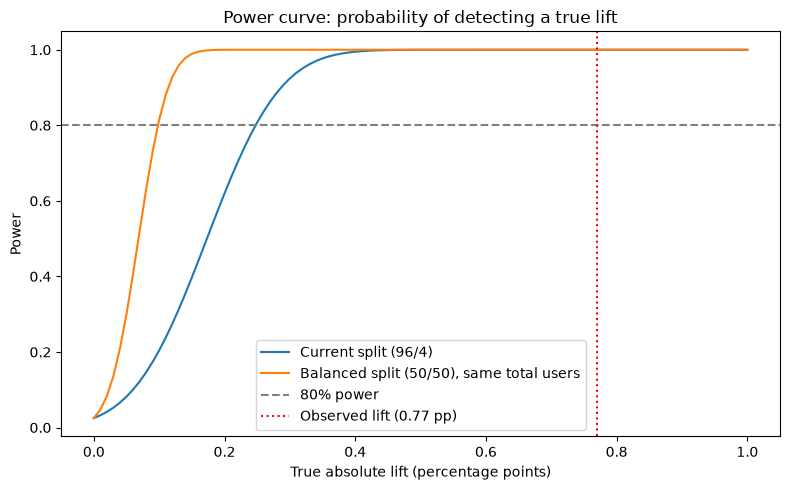

In [8]:
from pathlib import Path
import matplotlib.pyplot as plt

Path("reports/figures").mkdir(parents=True, exist_ok=True)

lifts = np.linspace(0, 0.01, 101)
n_half = (n1 + n2) / 2

power_current = [power_two_proportions(p_control + d, p_control, n1, n2) for d in lifts]
power_balanced = [power_two_proportions(p_control + d, p_control, n_half, n_half) for d in lifts]

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(lifts * 100, power_current, label="Current split (96/4)")
ax.plot(lifts * 100, power_balanced, label="Balanced split (50/50), same total users")
ax.axhline(0.8, linestyle="--", color="gray", label="80% power")
ax.axvline(abs_lift * 100, linestyle=":", color="red",
           label=f"Observed lift ({abs_lift * 100:.2f} pp)")
ax.set_xlabel("True absolute lift (percentage points)")
ax.set_ylabel("Power")
ax.set_title("Power curve: probability of detecting a true lift")
ax.legend()
plt.tight_layout()
plt.savefig("reports/figures/power_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
mde_balanced = mde_two_proportions(p_control, n_half, n_half)
print(f"MDE with current 96/4 split     : {mde_abs * 100:.3f} pp")
print(f"MDE with 50/50 split            : {mde_balanced * 100:.3f} pp")

MDE with current 96/4 split     : 0.247 pp
MDE with 50/50 split            : 0.097 pp


### Power analysis — interpretation
| | Value |
|---|---|
| Baseline (psa) conversion | 1.785% |
| MDE, current 96/4 split (80% power, α = 0.05) | 0.247 pp (≈13.8% relative) |
| MDE, hypothetical 50/50 split, same total users | 0.097 pp |
| Observed absolute lift | 0.769 pp |

- **The experiment is well-powered for the observed effect.** The
  observed lift is about 3× the MDE; power at that effect size is
  close to 100%.
- **Smaller effects could be missed.** True lifts below ~0.25 pp would
  likely go undetected. This matters for the segment analysis, where
  each segment has far fewer control users.
- **Design trade-off:** a 50/50 split would be ~2.5× more sensitive,
  but would move ~270K users from ads to PSA. At the observed lift,
  that is roughly 2,000 forgone conversions during the test. Given
  that the true effect is well above the MDE, the 96/4 split was a
  reasonable choice.

Note: post-hoc "observed power" is not reported, as it is a direct
transformation of the p-value and adds no new information.